## Week-lab2: Decision trees classifiers
**This lab**: the aim is to build and evaluate classification models for the titanic dataset based on decision trees classifiers, and to fine tune their hyperparameters using cross-validation. During this lab it is highly recommended to check the **sklearn** documentation on `class tree.DecisionTreeClassifier` to fit decision trees classifiers in Python, by simply typing in the name of function via [*scikit-learn* website](https://scikit-learn.org/stable/index.html).


In [11]:
try:
    import pandas
    import numpy
    import sklearn
    import matplotlib
except:
    !pip3 install pandas==2.2.2 numpy==1.26.4 scikit-learn==1.5.1 matplotlib==3.9.2

  Using cached pandas-2.2.2.tar.gz (4.4 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'


  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [12 lines of output]
      + meson setup C:\Users\iy25299\AppData\Local\Temp\pip-install-oujqv__8\pandas_185812528260494a94a26807dad0cd97 C:\Users\iy25299\AppData\Local\Temp\pip-install-oujqv__8\pandas_185812528260494a94a26807dad0cd97\.mesonpy-g7fdwngn\build -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --vsenv --native-file=C:\Users\iy25299\AppData\Local\Temp\pip-install-oujqv__8\pandas_185812528260494a94a26807dad0cd97\.mesonpy-g7fdwngn\build\meson-python-native-file.ini
      The Meson build system
      Version: 1.2.1
      Source dir: C:\Users\iy25299\AppData\Local\Temp\pip-install-oujqv__8\pandas_185812528260494a94a26807dad0cd97
      Build dir: C:\Users\iy25299\AppData\Local\Temp\pip-install-oujqv__8\pandas_185812528260494a94a26807dad0cd97\.mesonpy-g7fdwngn\build
      Build type: native build
      Project name: pandas
      Project version: 

### Install dependencies

In [20]:
# Import necessary libraries.
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import tree 
from sklearn.metrics import confusion_matrix, accuracy_score

import matplotlib.pyplot as plt

# Set up the RNG for numpy.random
RANDOM_SEED = 42
np.random.seed(seed=RANDOM_SEED)

### Load titanic dataset
Use **Pandas**’s `read_csv` command to load the `titanic.csv` file in a table. From this table extract a binary (0-1) vector y of labels/outcomes indicating a passenger had survived or not. Create a feature matrix X whose columns are *Pclass, Sex, Age, Siblings_SpousesAboard, Parents_ChildrenAboard, and Fare* features. You need to convert the Sex varialble (currently is string) into a 0-1 numerical variable to include it in the feature matrix.

In [ ]:
df = pd.read_csv('titanic(1).csv')
# your code to build x and y

y = df['Survived']

X = np.asarray(df[['Pclass', 'Sex', 'Age', 'Siblings_SpousesAboard', 'Parents_ChildrenAboard', 'Fare']])
X[X == 'male'] = 1
X[X == 'female'] = 0

0      0
1      1
2      1
3      1
4      0
      ..
882    0
883    1
884    0
885    1
886    0
Name: Survived, Length: 887, dtype: int64

### Split this data randomly into Train and Test sets with proportions 80%-20%.

In [21]:
data_train, data_test, labels_train, labels_test = train_test_split(X, y, test_size=0.2, random_state=42)
unique_label_count = pd.Series(y).nunique()

### Fit and Visualise decision trees for classification
Use sklearn command `tree.DecisionTreeClassifier` to fit decision trees to classify the train data with various `max_leaf_nodes` options. The number of leaves of a tree is equal to the number of splits plus one.

Visualise each tree model (e.g., named `clf`) using command `tree.plot_tree`.

[Text(0.5, 0.875, 'x[1] <= 0.5\ngini = 0.474\nsamples = 887\nvalue = [545, 342]'),
 Text(0.25, 0.625, 'x[0] <= 2.5\ngini = 0.383\nsamples = 314\nvalue = [81.0, 233.0]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'gini = 0.1\nsamples = 170\nvalue = [9, 161]'),
 Text(0.375, 0.375, 'gini = 0.5\nsamples = 144\nvalue = [72, 72]'),
 Text(0.75, 0.625, 'x[2] <= 13.0\ngini = 0.308\nsamples = 573\nvalue = [464, 109]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[3] <= 2.5\ngini = 0.493\nsamples = 41\nvalue = [18.0, 23.0]'),
 Text(0.5, 0.125, 'gini = 0.083\nsamples = 23\nvalue = [1, 22]'),
 Text(0.75, 0.125, 'gini = 0.105\nsamples = 18\nvalue = [17, 1]'),
 Text(0.875, 0.375, 'gini = 0.271\nsamples = 532\nvalue = [446, 86]')]

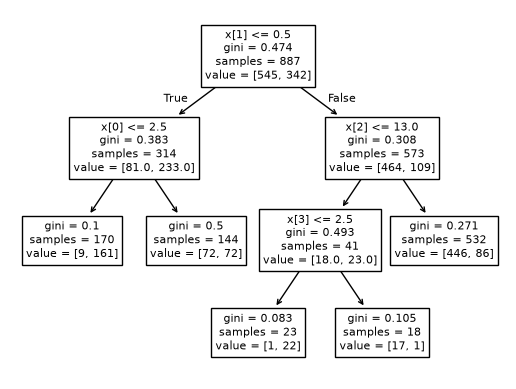

In [ ]:
# your code using tree.plot_tree()

clf5 = tree.DecisionTreeClassifier(max_leaf_nodes=5)
clf5.fit(X, y)
tree.plot_tree(clf5)

[Text(0.36666666666666664, 0.9166666666666666, 'x[1] <= 0.5\ngini = 0.474\nsamples = 887\nvalue = [545, 342]'),
 Text(0.13333333333333333, 0.75, 'x[0] <= 2.5\ngini = 0.383\nsamples = 314\nvalue = [81.0, 233.0]'),
 Text(0.25, 0.8333333333333333, 'True  '),
 Text(0.06666666666666667, 0.5833333333333334, 'gini = 0.1\nsamples = 170\nvalue = [9, 161]'),
 Text(0.2, 0.5833333333333334, 'x[5] <= 23.35\ngini = 0.5\nsamples = 144\nvalue = [72, 72]'),
 Text(0.13333333333333333, 0.4166666666666667, 'x[2] <= 36.5\ngini = 0.484\nsamples = 117\nvalue = [48, 69]'),
 Text(0.06666666666666667, 0.25, 'gini = 0.463\nsamples = 107\nvalue = [39, 68]'),
 Text(0.2, 0.25, 'gini = 0.18\nsamples = 10\nvalue = [9, 1]'),
 Text(0.26666666666666666, 0.4166666666666667, 'gini = 0.198\nsamples = 27\nvalue = [24, 3]'),
 Text(0.6, 0.75, 'x[2] <= 13.0\ngini = 0.308\nsamples = 573\nvalue = [464, 109]'),
 Text(0.4833333333333333, 0.8333333333333333, '  False'),
 Text(0.4666666666666667, 0.5833333333333334, 'x[3] <= 2.5\ngi

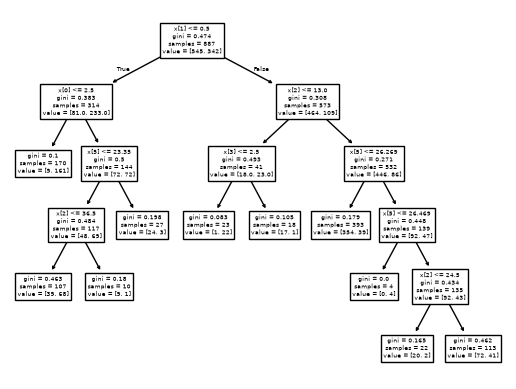

In [28]:
clf10 = tree.DecisionTreeClassifier(max_leaf_nodes=10)
clf10.fit(X, y)
tree.plot_tree(clf10)

[Text(0.6, 0.8333333333333334, 'x[1] <= 0.5\ngini = 0.474\nsamples = 887\nvalue = [545, 342]'),
 Text(0.4, 0.5, 'x[0] <= 2.5\ngini = 0.383\nsamples = 314\nvalue = [81.0, 233.0]'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'gini = 0.1\nsamples = 170\nvalue = [9, 161]'),
 Text(0.6, 0.16666666666666666, 'gini = 0.5\nsamples = 144\nvalue = [72, 72]'),
 Text(0.8, 0.5, 'gini = 0.308\nsamples = 573\nvalue = [464, 109]'),
 Text(0.7, 0.6666666666666667, '  False')]

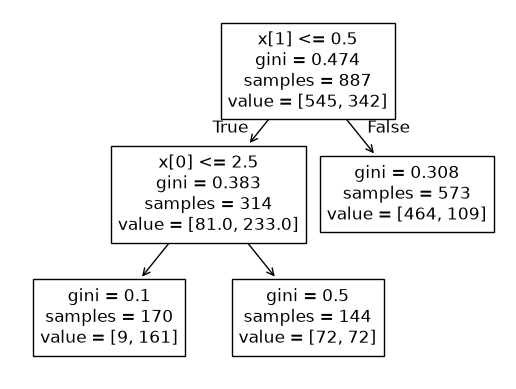

In [29]:
clf3 = tree.DecisionTreeClassifier(max_leaf_nodes=3)
clf3.fit(X, y)
tree.plot_tree(clf3)

In [ ]:
# compute the confusion matrix
y_pred = clf5.predict(X)
cm = confusion_matrix(y, y_pred)

In [ ]:
# your code here 


718.0


Use information from confusion matrix to compute and print the classification accuracy, precision and recall, evaluated on the train and test data. You can also import other functions from `sklearn.metrics` (e.g., accuracy_score).

In [41]:
from sklearn.metrics import precision_score, recall_score

# your code here
print(accuracy_score(y, y_pred, normalize=False))
print(precision_score(y, y_pred))
print(recall_score(y, y_pred))

718.0
0.9481865284974094
0.5350877192982456


### Cross validation
Split the train data further randomly into train & validation proportions 80%-20%, to perform a cross validation step. Plot the Validation Curves displaying the classification accuracies on the train & validation data against the model complexity, here, the tree's hyperparameter `max_leaf_nodes` ranging from 2 to 200.

[  2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19
  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36  37
  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108 109
 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127
 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145
 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163
 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181
 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199]
[0.7954144620811288, 0.8077601410934744, 0.8201058201058201, 0.8218694885361552, 0.8412698412698413, 0.8412698412698413, 0.8536155202821869, 0.8536155202821869, 0.8606701940035273, 0.8606701940035

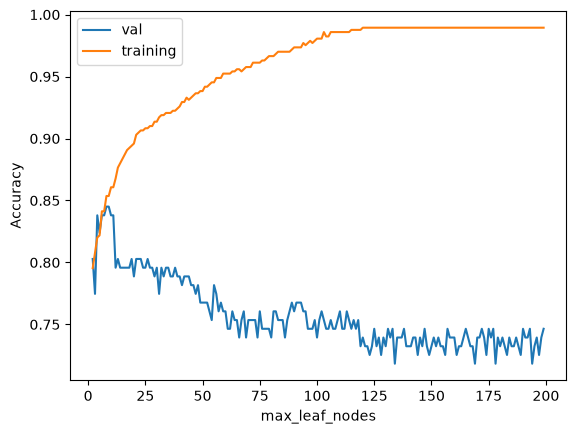

In [ ]:
P_CV = 0.2
MAX_LEAF = 200

data_train_CV, data_val_CV, labels_train_CV, labels_val_CV = train_test_split(data_train, labels_train, test_size=P_CV, random_state=RANDOM_SEED)

# your code here

maxes = np.arange(2,MAX_LEAF,1)
# print(maxes)

train_accuracies = []
val_accuracies = []

for max in maxes:
    clf_cv = tree.DecisionTreeClassifier(max_leaf_nodes=max)
    clf_cv.fit(data_train_CV, labels_train_CV)
    pred_labels_train = clf_cv.predict(data_train_CV)
    pred_val_train = clf_cv.predict(data_val_CV)

    train_accuracies.append(accuracy_score(labels_train_CV, pred_labels_train, normalize=True))
    val_accuracies.append(accuracy_score(labels_val_CV, pred_val_train, normalize=True))

print(train_accuracies)
print(val_accuracies)


plt.plot(maxes, val_accuracies, label='val')
plt.plot(maxes, train_accuracies, label='training')
plt.xlabel("max_leaf_nodes"); plt.ylabel("Accuracy"); plt.legend()


Can you see the over/underfitting cases in your validtion curves?
What's the best `max_leaf_nodes` number for the decision tree? Implement a grid search to find this optimal hyperparamter so that it maximises the validation accuracy.

In [77]:
# your code here
print('best is', maxes[np.argmax(val_accuracies)])

best is 8


### Repeat Cross validation 50 times to get smoother results
You might also want to make better use of all of the data, perhaps the 20% we picked here for validation just happen to be particularly difficult examples? We can get a better estimate of how the entire dataset will perform if we perform multiple rounds of cross validation. Therefore in this part, repeat the random train-validation split and the associated cross validation procedure for 50 times. Average the Validation Curves over these 10 runs. Do you see smoother results?

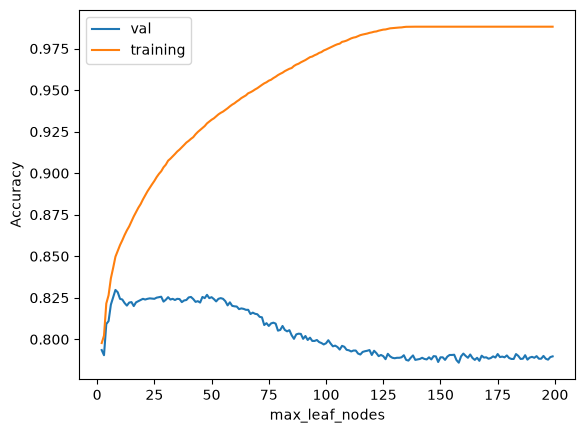

In [98]:
RUNS = 50
MAX_LEAF = 200

# your code here

maxes = np.arange(2,MAX_LEAF,1)

running_train_acc = np.zeros(len(maxes))
running_val_acc = np.zeros(len(maxes))


for run in range(RUNS):
    data_train_CV, data_val_CV, labels_train_CV, labels_val_CV = train_test_split(data_train, labels_train, test_size=P_CV)
    for max_idx in range(len(maxes)):
        max = maxes[max_idx]
        clf_cv = tree.DecisionTreeClassifier(max_leaf_nodes=max)
        clf_cv.fit(data_train_CV, labels_train_CV)
        pred_labels_train = clf_cv.predict(data_train_CV)
        pred_val_train = clf_cv.predict(data_val_CV)

        # train_accuracies.append(accuracy_score(labels_train_CV, pred_labels_train, normalize=True))
        # val_accuracies.append(accuracy_score(labels_val_CV, pred_val_train, normalize=True))

        train_acc = accuracy_score(labels_train_CV, pred_labels_train, normalize=True)
        val_acc = accuracy_score(labels_val_CV, pred_val_train, normalize=True)

        running_train_acc[max_idx] += (train_acc - running_train_acc[max_idx]) / (run + 1)
        running_val_acc[max_idx] += (val_acc - running_val_acc[max_idx]) / (run + 1)
    
plt.plot(maxes, running_val_acc, label='val')
plt.plot(maxes, running_train_acc, label='training')
plt.xlabel("max_leaf_nodes"); plt.ylabel("Accuracy"); plt.legend()

Run a hyperparamter grid search on these averaged validation accuracies to determine the best number for the tree's `max_leaf_nodes`.

In [99]:
# your code here
print('best is', maxes[np.argmax(running_val_acc)])

best is 8


Use this optimal parameter to train a decision tree on whole training data, report the classification accuracies for the training and testing datasets. 

[Text(0.4230769230769231, 0.9, 'x[1] <= 0.5\ngini = 0.474\nsamples = 887\nvalue = [545, 342]'),
 Text(0.15384615384615385, 0.7, 'x[0] <= 2.5\ngini = 0.383\nsamples = 314\nvalue = [81.0, 233.0]'),
 Text(0.28846153846153844, 0.8, 'True  '),
 Text(0.07692307692307693, 0.5, 'gini = 0.1\nsamples = 170\nvalue = [9, 161]'),
 Text(0.23076923076923078, 0.5, 'x[5] <= 23.35\ngini = 0.5\nsamples = 144\nvalue = [72, 72]'),
 Text(0.15384615384615385, 0.3, 'x[2] <= 36.5\ngini = 0.484\nsamples = 117\nvalue = [48, 69]'),
 Text(0.07692307692307693, 0.1, 'gini = 0.463\nsamples = 107\nvalue = [39, 68]'),
 Text(0.23076923076923078, 0.1, 'gini = 0.18\nsamples = 10\nvalue = [9, 1]'),
 Text(0.3076923076923077, 0.3, 'gini = 0.198\nsamples = 27\nvalue = [24, 3]'),
 Text(0.6923076923076923, 0.7, 'x[2] <= 13.0\ngini = 0.308\nsamples = 573\nvalue = [464, 109]'),
 Text(0.5576923076923077, 0.8, '  False'),
 Text(0.5384615384615384, 0.5, 'x[3] <= 2.5\ngini = 0.493\nsamples = 41\nvalue = [18.0, 23.0]'),
 Text(0.461538

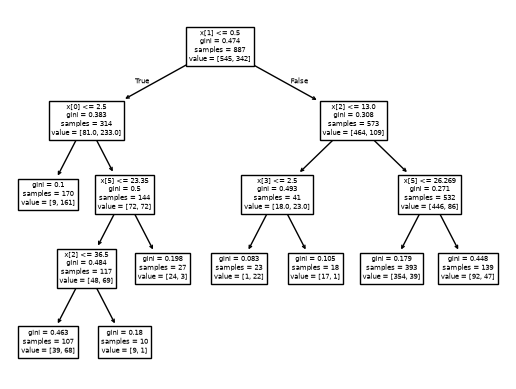

In [102]:
# your code here
opt_clf = tree.DecisionTreeClassifier(max_leaf_nodes=8)
opt_clf.fit(X, y)
tree.plot_tree(opt_clf)

In [107]:
labels_pred = opt_clf.predict(X)
opt_cm = confusion_matrix(y, labels_pred)
print( accuracy_score(y, labels_pred, normalize=False))

747.0
